# US5 — Exploratory Data Analysis

**Jira:** SCRUM-10 · **Sprint 2** · **Owner:** Nuray

Run `01_data_pipeline_and_eda.ipynb` first — this notebook reads what it writes.

**Colour rule for the whole notebook:** blue `#2a78d6` = passed, red `#e34948`
= at risk, everywhere, without exception. The pair was checked with a palette
validator: it stays distinguishable under colour-blind simulation
(ΔE 21.6 protan) and both colours clear 3:1 contrast against the background.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# --- palette -------------------------------------------------------------
OK, RISK = '#2a78d6', '#e34948'      # passed / at risk
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
SURFACE = '#fcfcfb'
NEUTRAL = '#c9c8c3'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'legend.frameon': False, 'figure.dpi': 110,
})

KEY = ['code_module', 'code_presentation', 'id_student']

In [3]:
df = pd.read_csv('../data/processed/final_model_data.csv')
weekly = pd.read_csv('../data/processed/weekly_activity.csv')
features = open('../data/processed/feature_columns.txt').read().split()

# final_result is not a feature, but for EDA we want the four original
# categories, so we read them back from the raw table
info = pd.read_csv('../data/raw/studentInfo.csv', na_values=['?'])
df = df.merge(info[KEY + ['final_result']], on=KEY, how='left')

print(f'{len(df):,} students · {len(features)} features · '
      f'at_risk {df.at_risk.mean():.1%}')

9,700 students · 16 features · at_risk 44.0%


## The numbers in one line

In [5]:
n = len(df)
at_risk = df.at_risk.sum()
withdrawn = (df.final_result == 'Withdrawn').sum()
silent = (df.silent_weeks >= 3).sum()
no_work = (df.n_submitted == 0).sum()

print(f'students                              {n:>8,}')
print(f'at risk (fail or withdraw)            {at_risk:>8,}   {at_risk/n:>6.1%}')
print(f'  of them, withdrew                   {withdrawn:>8,}   {withdrawn/n:>6.1%}')
print(f'silent 3+ weeks out of 6              {silent:>8,}   {silent/n:>6.1%}')
print(f'submitted nothing by week 6           {no_work:>8,}   {no_work/n:>6.1%}')
print(f'  of those, at risk                   {df[df.n_submitted==0].at_risk.mean():>14.1%}')

students                                 9,700
at risk (fail or withdraw)               4,268    44.0%
  of them, withdrew                      1,722    17.8%
silent 3+ weeks out of 6                 1,861    19.2%
submitted nothing by week 6                783     8.1%
  of those, at risk                            95.4%


## 1. How the course ends

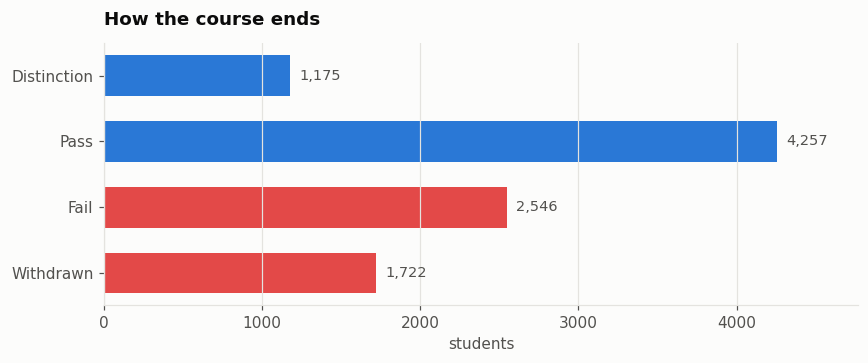

In [7]:
order = ['Distinction', 'Pass', 'Fail', 'Withdrawn']
vc = df.final_result.value_counts().reindex(order)
colors = [OK, OK, RISK, RISK]

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.barh(order[::-1], vc[::-1].values, color=colors[::-1], height=.62)
for bar, v in zip(bars, vc[::-1].values):
    ax.text(v + n*0.006, bar.get_y() + bar.get_height()/2, f'{v:,}',
            va='center', fontsize=9.5, color=MUTED)
ax.set_title('How the course ends')
ax.set_xlim(0, vc.max() * 1.12)
ax.grid(axis='y', visible=False)
ax.set_xlabel('students')
plt.tight_layout(); plt.show()

Distinction and Pass are the successful half, Fail and Withdrawn are what we
predict. Withdrawals matter as much as failures: a student who quietly leaves
is exactly the one an early warning could have reached.

## 2. When the two groups separate

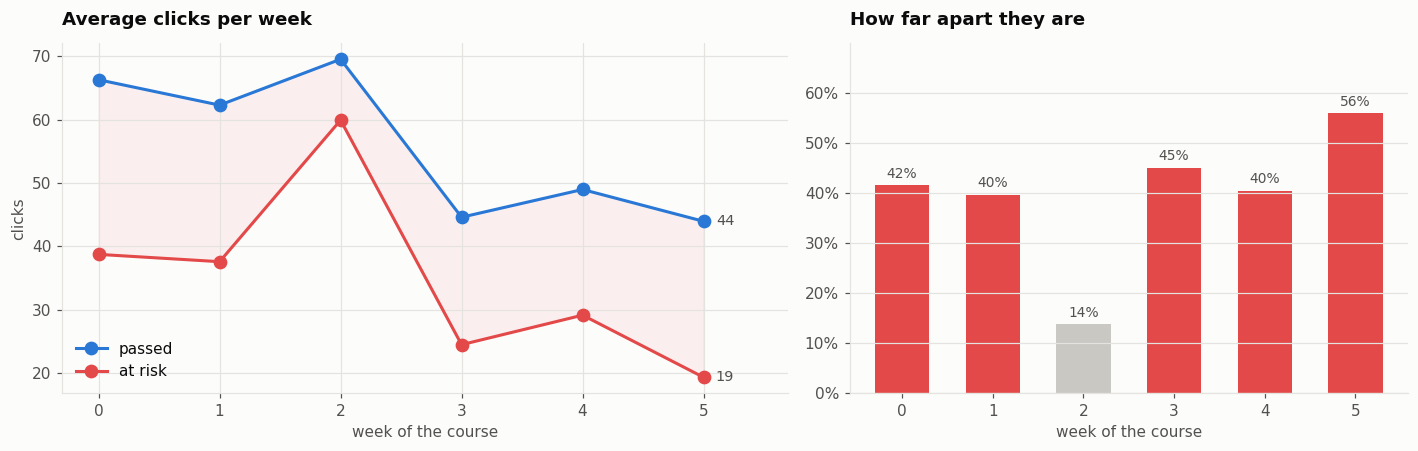

In [10]:
m = weekly.merge(df[KEY + ['at_risk']], on=KEY, how='inner')
curve = m.groupby(['week', 'at_risk'])['total_clicks'].mean().unstack()
gap = (curve[0] - curve[1]) / curve[0] * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2),
                             gridspec_kw={'width_ratios': [1.3, 1]})

a1.fill_between(curve.index, curve[0], curve[1], color=RISK, alpha=.07)
a1.plot(curve.index, curve[0], marker='o', ms=8, lw=2, color=OK, label='passed')
a1.plot(curve.index, curve[1], marker='o', ms=8, lw=2, color=RISK, label='at risk')
for x, yv, c in [(curve.index[-1], curve[0].iloc[-1], OK),
                 (curve.index[-1], curve[1].iloc[-1], RISK)]:
    a1.annotate(f'{yv:.0f}', (x, yv), xytext=(8, 0), textcoords='offset points',
                va='center', fontsize=9.5, color=MUTED)
a1.set_title('Average clicks per week')
a1.set_xlabel('week of the course'); a1.set_ylabel('clicks')
a1.set_xlim(-.3, curve.index.max() + .7)
a1.legend(loc='lower left')

bar_colors = [NEUTRAL if v < 30 else RISK for v in gap.values]
a2.bar(gap.index, gap.values, color=bar_colors, width=.6)
for x, v in zip(gap.index, gap.values):
    a2.text(x, v + 1.5, f'{v:.0f}%', ha='center', fontsize=9, color=MUTED)
a2.set_title('How far apart they are')
a2.set_xlabel('week of the course')
a2.yaxis.set_major_formatter(PercentFormatter())
a2.set_ylim(0, gap.max() * 1.25)
a2.grid(axis='x', visible=False)

plt.tight_layout(); plt.show()

**The single most important chart in this notebook.**

The groups are already 42 % apart in **week 0**. The gap does not build up
slowly — students who will fail start the course less engaged.

Week 2 is the exception: both groups spike, almost certainly before the first
assessment, and the gap collapses to 14 %. A prediction point placed there
would work noticeably worse than one placed anywhere else.

From week 3 the at-risk group falls away and by week 5 the gap is 56 %.

## 3. Is week 6 the right prediction point?

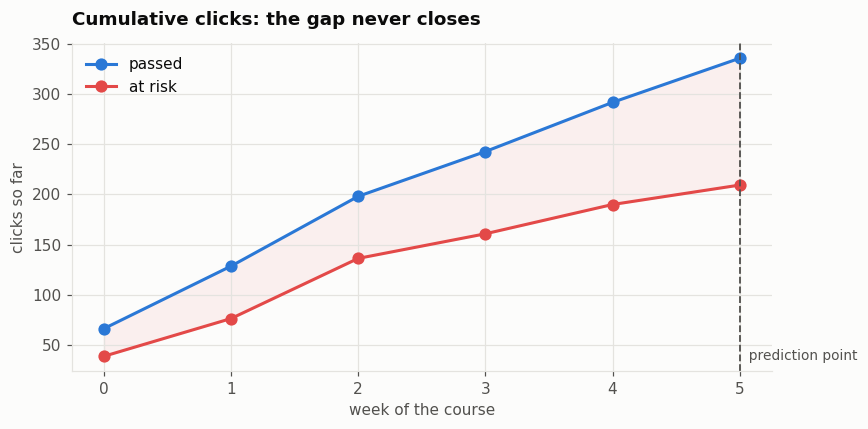

In [13]:
# Cumulative clicks: how much of the signal has accumulated by each week
cum = m.sort_values('week').groupby(['at_risk', 'week'])['total_clicks'].mean() \
       .groupby(level=0).cumsum().unstack(0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cum.index, cum[0], marker='o', ms=7, lw=2, color=OK, label='passed')
ax.plot(cum.index, cum[1], marker='o', ms=7, lw=2, color=RISK, label='at risk')
ax.fill_between(cum.index, cum[0], cum[1], color=RISK, alpha=.07)
ax.axvline(5, ls='--', lw=1.2, color=MUTED)
ax.text(5, ax.get_ylim()[1]*.1, '  prediction point', fontsize=9, color=MUTED)
ax.set_title('Cumulative clicks: the gap never closes')
ax.set_xlabel('week of the course'); ax.set_ylabel('clicks so far')
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

Cumulatively the two groups separate from the start and never come back
together. The signal is there long before week 6, which means **an earlier
prediction point is worth testing** — a warning in week 3 is worth more to a
curator than the same warning in week 6. This goes into US7.

## 4. Does the pattern hold in every course?

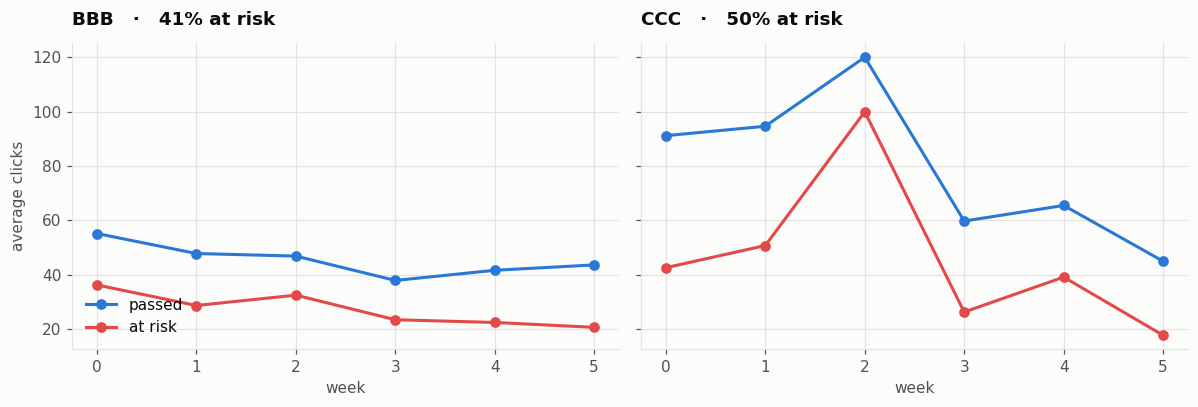

In [16]:
mods = sorted(df.code_module.unique())
fig, axes = plt.subplots(1, len(mods), figsize=(5.5*len(mods), 3.8), sharey=True)
axes = np.atleast_1d(axes)

for ax, mod in zip(axes, mods):
    sub = m[m.code_module == mod].groupby(['week', 'at_risk'])['total_clicks'].mean().unstack()
    ax.plot(sub.index, sub[0], marker='o', ms=6, lw=2, color=OK, label='passed')
    ax.plot(sub.index, sub[1], marker='o', ms=6, lw=2, color=RISK, label='at risk')
    rate = df[df.code_module == mod].at_risk.mean()
    ax.set_title(f'{mod}   ·   {rate:.0%} at risk')
    ax.set_xlabel('week')
axes[0].set_ylabel('average clicks')
axes[0].legend(loc='lower left')
plt.tight_layout(); plt.show()

Small multiples, one per course. The separation is there in both, but the
shape is not the same: the week-2 spike that flattened the overall gap comes
almost entirely from one course. A single average can hide this — which is
also why the model is evaluated on whole presentations rather than on a random
row split.

## 5. Activity translates into risk almost linearly

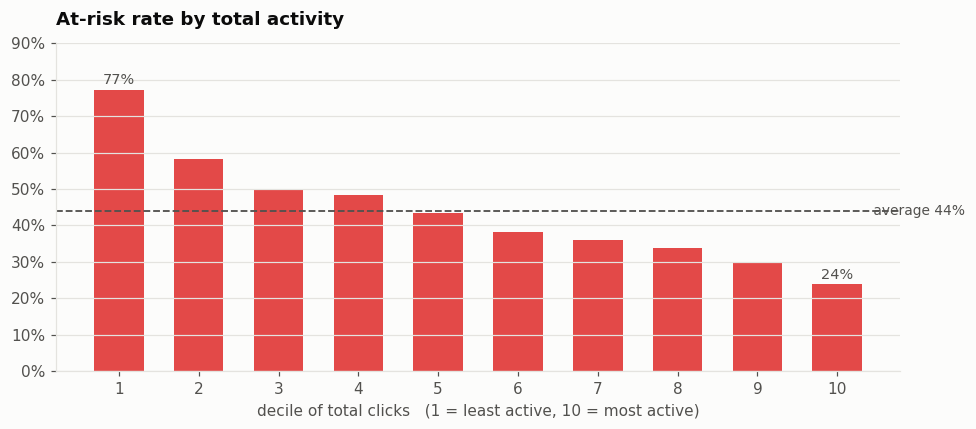

In [19]:
d = df.copy()
d['decile'] = pd.qcut(d.total_clicks, 10, labels=False, duplicates='drop') + 1
rate = d.groupby('decile')['at_risk'].mean() * 100
overall = df.at_risk.mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(rate.index, rate.values, color=RISK, width=.62)
ax.axhline(overall, ls='--', lw=1.2, color=MUTED)
ax.text(10.4, overall, f' average {overall:.0f}%', va='center',
        fontsize=9, color=MUTED)
for x, v in [(rate.index[0], rate.iloc[0]), (rate.index[-1], rate.iloc[-1])]:
    ax.text(x, v + 1.5, f'{v:.0f}%', ha='center', fontsize=9.5, color=MUTED)
ax.set_title('At-risk rate by total activity')
ax.set_xlabel('decile of total clicks   (1 = least active, 10 = most active)')
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xticks(range(1, 11))
ax.set_ylim(0, 90)
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

Among the least active tenth of students, **77 % fail or withdraw**. Among
the most active tenth, 24 %. The relationship is close to monotonic, which is
why even a simple model works here.

## 6. Silent weeks and missed work

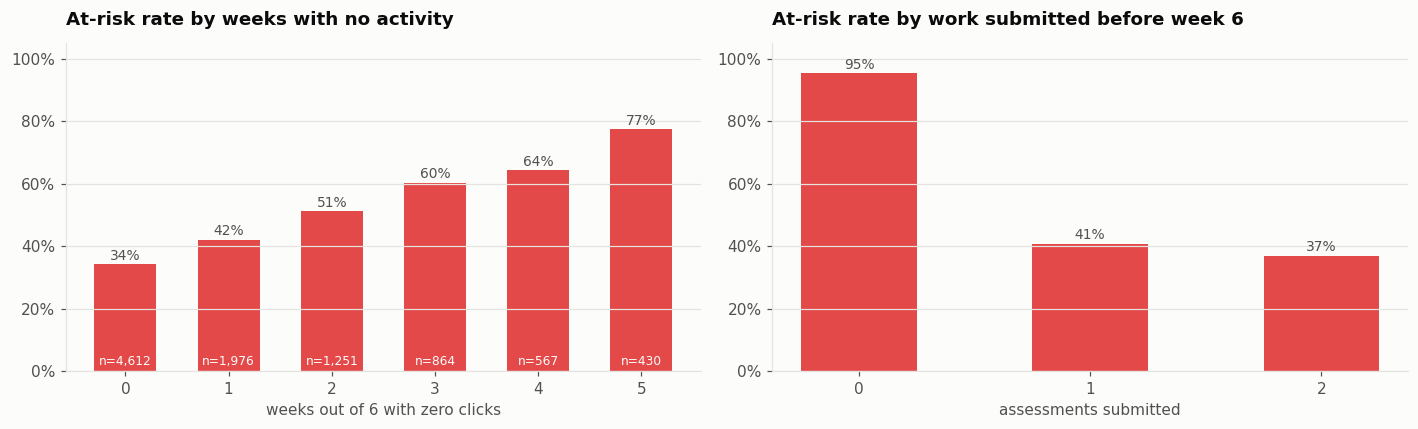

In [22]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))

s = df.groupby('silent_weeks')['at_risk'].agg(['mean', 'size'])
s = s[s['size'] >= 30]
a1.bar(s.index, s['mean']*100, color=RISK, width=.6)
for x, v, nn in zip(s.index, s['mean']*100, s['size']):
    a1.text(x, v + 1.5, f'{v:.0f}%', ha='center', fontsize=9, color=MUTED)
    a1.text(x, 2, f'n={nn:,}', ha='center', fontsize=8, color=SURFACE)
a1.set_title('At-risk rate by weeks with no activity')
a1.set_xlabel('weeks out of 6 with zero clicks')
a1.yaxis.set_major_formatter(PercentFormatter())
a1.set_ylim(0, 105); a1.grid(axis='x', visible=False)

sub = df.groupby('n_submitted')['at_risk'].agg(['mean', 'size'])
sub = sub[sub['size'] >= 30]
a2.bar(sub.index, sub['mean']*100, color=RISK, width=.5)
for x, v in zip(sub.index, sub['mean']*100):
    a2.text(x, v + 1.5, f'{v:.0f}%', ha='center', fontsize=9, color=MUTED)
a2.set_title('At-risk rate by work submitted before week 6')
a2.set_xlabel('assessments submitted')
a2.yaxis.set_major_formatter(PercentFormatter())
a2.set_ylim(0, 105); a2.set_xticks(sub.index)
a2.grid(axis='x', visible=False)

plt.tight_layout(); plt.show()

Two blunt signals. Six silent weeks out of six means the outcome is close to
certain. Submitting nothing by week 6 is almost as strong.

Both are things a human could notice — the point of the model is to also catch
the students who are *partly* engaged, where the eye cannot judge.

## 7. Scores separate the groups, but there are few of them yet

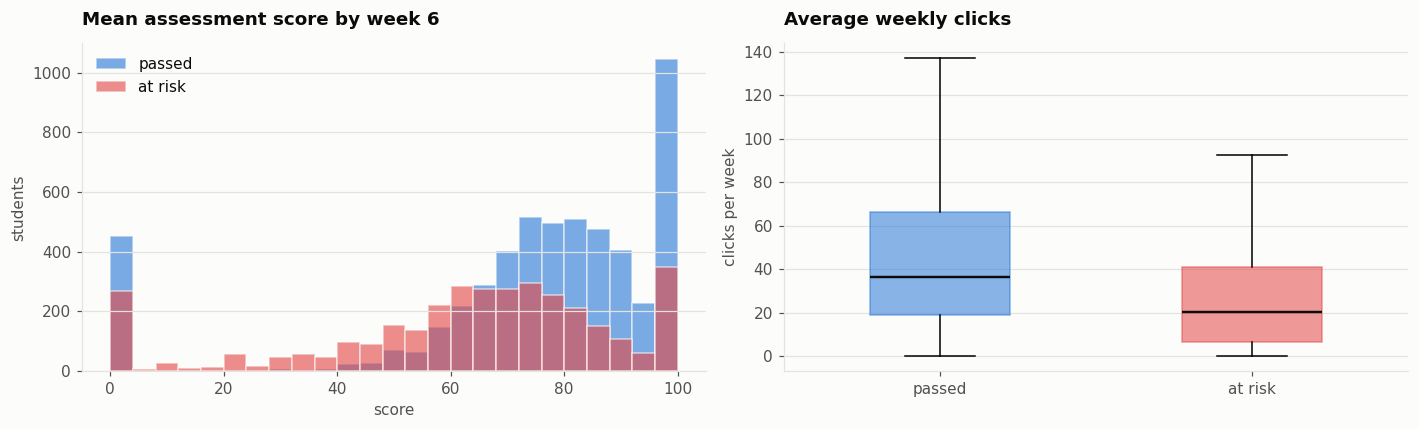

In [25]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))

bins = np.linspace(0, 100, 26)
for value, color, label in [(0, OK, 'passed'), (1, RISK, 'at risk')]:
    sub = df[(df.at_risk == value) & (df.n_submitted > 0)]['mean_score']
    a1.hist(sub, bins=bins, alpha=.62, color=color, label=label, edgecolor=SURFACE)
a1.set_title('Mean assessment score by week 6')
a1.set_xlabel('score'); a1.set_ylabel('students'); a1.legend()
a1.grid(axis='x', visible=False)

parts = [df[df.at_risk == 0]['avg_weekly_clicks'],
         df[df.at_risk == 1]['avg_weekly_clicks']]
bp = a2.boxplot(parts, showfliers=False, widths=.45, patch_artist=True,
                medianprops=dict(color=INK, lw=1.6))
for patch, color in zip(bp['boxes'], [OK, RISK]):
    patch.set_facecolor(color); patch.set_alpha(.55); patch.set_edgecolor(color)
a2.set_xticks([1, 2]); a2.set_xticklabels(['passed', 'at risk'])
a2.set_title('Average weekly clicks')
a2.set_ylabel('clicks per week'); a2.grid(axis='x', visible=False)

plt.tight_layout(); plt.show()

In [26]:
print('assessments submitted by week 6:')
print(df.n_submitted.value_counts().sort_index().to_string())

assessments submitted by week 6:
n_submitted
0.0     783
1.0    5917
2.0    3000


Scores separate the groups well, but by week 6 only one or two items are due,
so most of the predictive weight has to come from activity. This is a direct
argument for testing a later prediction point as well as an earlier one.

## 8. What correlates with risk

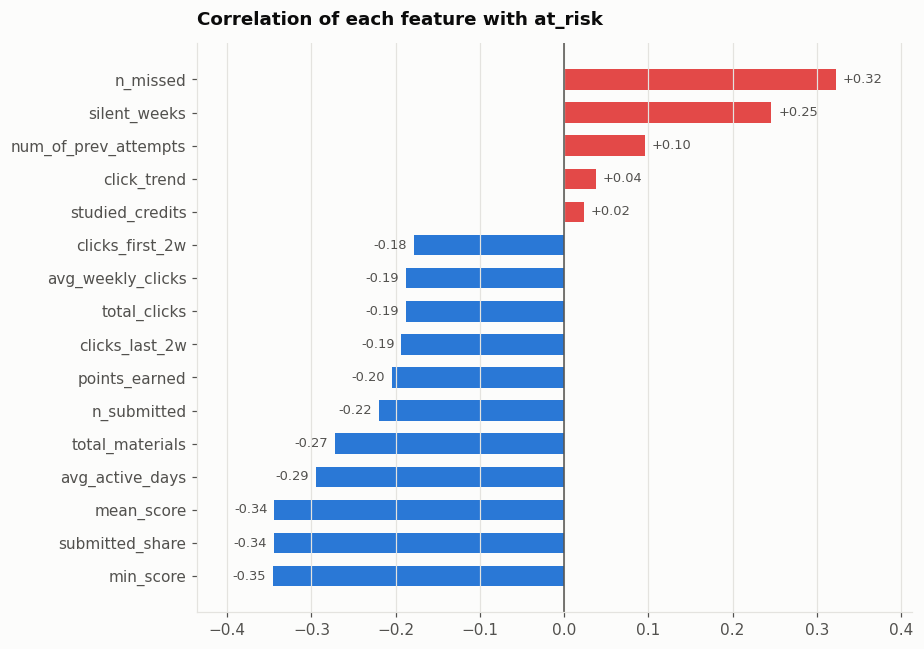

In [29]:
corr = df[features + ['at_risk']].corr()['at_risk'].drop('at_risk').sort_values()

fig, ax = plt.subplots(figsize=(8.5, 6))
colors = [RISK if v > 0 else OK for v in corr.values]
ax.barh(corr.index, corr.values, color=colors, height=.62)
ax.axvline(0, lw=1, color=MUTED)
for i, v in enumerate(corr.values):
    off = 0.008 if v > 0 else -0.008
    ax.text(v + off, i, f'{v:+.2f}', va='center',
            ha='left' if v > 0 else 'right', fontsize=8.5, color=MUTED)
ax.set_title('Correlation of each feature with at_risk')
ax.set_xlim(corr.min() - .09, corr.max() + .09)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

Red bars push risk up, blue bars pull it down. Nothing is above 0.35 on its
own, which is the usual picture: no single feature decides the outcome, the
model has to combine them.

## 9. The cohorts are not interchangeable

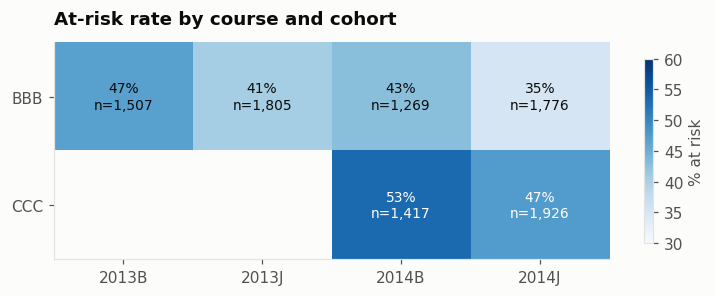

In [32]:
pivot = df.pivot_table(index='code_module', columns='code_presentation',
                       values='at_risk', aggfunc='mean') * 100
counts = df.pivot_table(index='code_module', columns='code_presentation',
                        values='at_risk', aggfunc='size')

fig, ax = plt.subplots(figsize=(7, 2.8))
im = ax.imshow(pivot.values, cmap='Blues', vmin=30, vmax=60, aspect='auto')
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.0f}%\nn={counts.values[i, j]:,.0f}',
                    ha='center', va='center', fontsize=9,
                    color='white' if v > 47 else INK)
ax.set_title('At-risk rate by course and cohort')
ax.grid(False)
fig.colorbar(im, ax=ax, label='% at risk', shrink=.85)
plt.tight_layout(); plt.show()

The base rate moves between 40 % and 50 % depending on the cohort. That is
why the model is evaluated by holding out one whole presentation at a time:
a random split would mix cohorts and make the result look steadier than it is.

## Findings — write these into `docs/`

1. **44 % of students are at risk**; the classes are close to balanced, no
   resampling needed.
2. **The groups are already apart in week 0** — a 42 % gap in clicks. Students
   who will fail start the course less engaged, the gap does not build slowly.
3. **Week 2 is a trap.** Both groups spike before the first assessment and the
   gap narrows to 14 %. A prediction point there would be the worst choice.
4. **The gap grows to 56 % by week 5** and cumulatively never closes.
5. **Activity maps onto risk almost monotonically**: 77 % at risk in the least
   active decile against 24 % in the most active one.
6. **Six silent weeks or zero submitted work** make the outcome close to
   certain; the value of the model is in the partly engaged middle.
7. **Only one or two assessments are due by week 6**, so activity carries most
   of the signal. Worth testing week 8 or 10 — and, because the signal exists
   from week 1, week 3 or 4 as well.
8. **Cohorts differ**: the base rate moves between 40 % and 50 %, which is why
   evaluation holds out whole presentations.